In [ ]:
import numpy as np
import scipy
import matplotlib.pyplot as plt
print("numpy:", np.__version__)
print("scipy:", scipy.__version__)
print("all good")

# Hodgkin-Huxley Neuron Simulator
 Notebook 01 — Model Implementation This notebook implements the Hodgkin-Huxley (1952) model from scratch. 
The model describes how action potentials are initiated and propagated
in neurons through the dynamics of voltage-gated ion channels.

## I will: 
 1. Implement the four coupled ODEs that define the model
2. Solve them numerically using `scipy.integrate.solve_ivp`
3. Reproduce the classic action potential waveform
4. Validate our output against the original 1952 figures

# the four variables

The model tracks four quantities simultaneously:

| Variable | Meaning | Range |
|----------|---------|-------|
| `V` | Membrane voltage (mV) | ~ -90 to +50 |
| `m` | Na⁺ activation gate | 0 to 1 |
| `h` | Na⁺ inactivation gate | 0 to 1 |
| `n` | K⁺ activation gate | 0 to 1 |

#At every moment in time, each variable evolves according to a differential equation derived from experimental measurements. 

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

plt.rcParams['figure.figsize'] = (12, 4)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

# The channel kinetics

Each gating variable has an alpha and beta rate function,
derived empirically by Hodgkin and Huxley from squid axon recordings.
These rates depend on the current membrane voltage.

# The channel kinetics 

alpha_m, beta_m — sodium opens fast when voltage rises, this is the spike upstroke
alpha_h, beta_h — sodium self-inactivates after opening, this is why spikes end
alpha_n, beta_n — potassium opens slowly after sodium, this is what pulls voltage back down


In [19]:
# HH rate functions and All units: V in mV, time in ms, current in µA/cm²

def alpha_m(V): return 0.1 * (25 - V) / (np.exp((25 - V) / 10) - 1)
def beta_m(V):  return 4.0 * np.exp(-V / 18)

def alpha_h(V): return 0.07 * np.exp(-V / 20)
def beta_h(V):  return 1.0 / (np.exp((30 - V) / 10) + 1)

def alpha_n(V): return 0.01 * (10 - V) / (np.exp((10 - V) / 10) - 1)
def beta_n(V):  return 0.125 * np.exp(-V / 80)

# The ODEs

#The membrane voltage changes according to the balance of ionic currents:

- **I_Na** sodium current (fast, responsible for the upstroke)
- **I_K** potassium current (slower, responsible for repolarisation)
- **I_L** leak current (passive, always present)
- **I_ext** externally injected current (our stimulus)

In [14]:
# Model parameters
C_m  = 1.0    # membrane capacitance (µF/cm²)
g_Na = 120.0  # max Na conductance (mS/cm²)
g_K  = 36.0   # max K conductance (mS/cm²)
g_L  = 0.3    # leak conductance (mS/cm²)
E_Na = 115.0  # Na reversal potential (mV)
E_K  = -12.0  # K reversal potential (mV)
E_L  = 10.6   # leak reversal potential (mV)

def hodgkin_huxley(t, state, I_ext):
    V, m, h, n = state

    I_Na = g_Na * m**3 * h * (V - E_Na)
    I_K  = g_K  * n**4      * (V - E_K)
    I_L  = g_L              * (V - E_L)

    dV = (I_ext - I_Na - I_K - I_L) / C_m
    dm = alpha_m(V) * (1 - m) - beta_m(V) * m
    dh = alpha_h(V) * (1 - h) - beta_h(V) * h
    dn = alpha_n(V) * (1 - n) - beta_n(V) * n

    return [dV, dm, dh, dn]

# Running the simulation

We set the initial conditions to resting state and inject a step current.
The solver advances the system in small time steps and returns the trajectory.

In [39]:
# Initial conditions (resting state)
V0 = 0.0    # resting voltage in HH convention (shifted, 0 = -65mV)
m0 = alpha_m(V0) / (alpha_m(V0) + beta_m(V0))
h0 = alpha_h(V0) / (alpha_h(V0) + beta_h(V0))
n0 = alpha_n(V0) / (alpha_n(V0) + beta_n(V0))

initial_state = [V0, m0, h0, n0]

# Time vector
t_start, t_end = 0, 50   # ms
t_eval = np.linspace(t_start, t_end, 5000)

# Injected current
I_ext =10.0 # µA/cm² — try changing this

# Solve
sol = solve_ivp(
    hodgkin_huxley,
    [t_start, t_end],
    initial_state,
    t_eval=t_eval,
    args=(I_ext,),
    method='RK45',
    max_step=0.05
)

V_trace = sol.y[0]

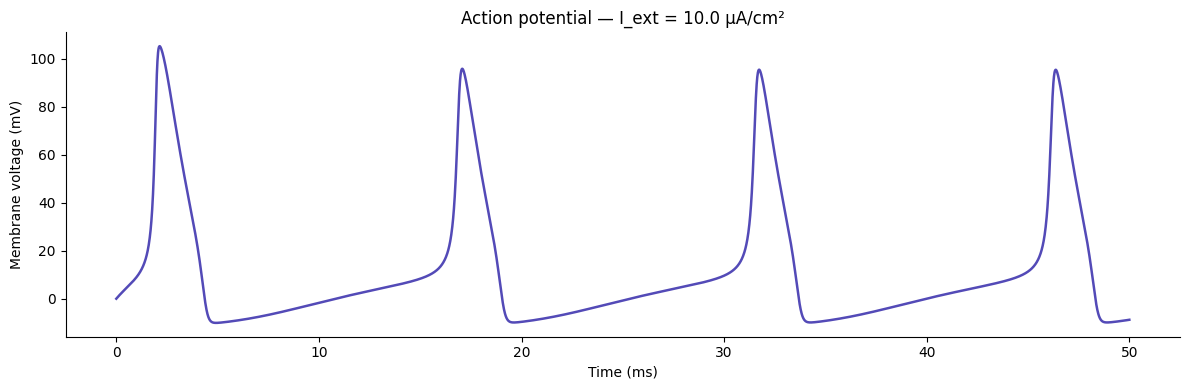

In [40]:
# --- Plot ---
fig, ax = plt.subplots()
ax.plot(sol.t, V_trace, color='#534AB7', linewidth=1.8)
ax.set_xlabel('Time (ms)')
ax.set_ylabel('Membrane voltage (mV)')
ax.set_title(f'Action potential — I_ext = {I_ext} µA/cm²')
plt.tight_layout()
plt.savefig('../figures/action_potential.png', dpi=150)
plt.show()